# Practical 1: Feature Engineering (Missing Values, Encoding, Scaling)

**Aim:** Prepare a clean, model-ready dataset by handling missing values, encoding categorical variables and scaling numerical columns.

**Dataset:** Titanic (built into seaborn, needs internet the first time). It has missing values, text columns and numbers on very different scales.

**Steps:** 1) Load and look at the data  2) Fill missing values  3) Encode text columns as numbers  4) Split into train and test  5) Scale the numbers  6) Check the result

## Step 1: Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

df = sns.load_dataset("titanic")
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### Look at the missing values

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


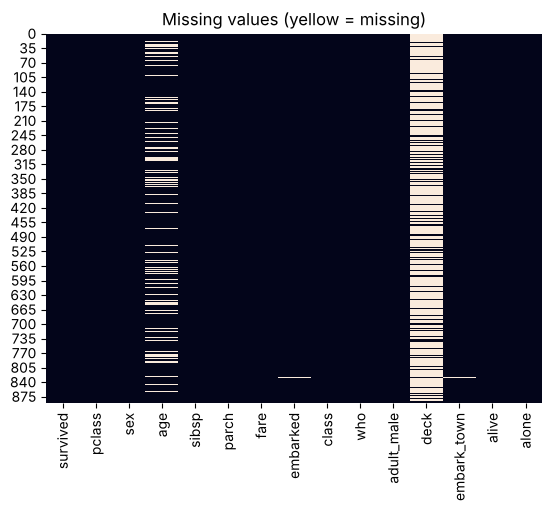

In [2]:
print(df.isnull().sum())

# Graph: yellow lines are missing values
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing values (yellow = missing)")
plt.show()

**How to read:** each column is a feature and each row is a passenger. Yellow means missing. `deck` is almost all yellow (about 77% missing), `age` has some yellow (about 20%) and `embarked` has just 2.

## Step 2: Fill the missing values

In [3]:
# Keep only the useful columns (the others just repeat the same information)
data = df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()

# age is a number -> fill with the median
data["age"] = data["age"].fillna(data["age"].median())

# embarked is a category -> fill with the most common value (mode)
data["embarked"] = data["embarked"].fillna(data["embarked"].mode()[0])

print(data.isnull().sum())   # all zeros now

survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


- **Median** for numbers (it is not affected by extreme values).  **Mode** for categories (most common value).
- We dropped `deck` because about 77% of it is missing, so filling it would mean inventing most of the data.

## Step 3: Encode the text columns

In [4]:
# Label encoding: sex has only 2 values -> 0 and 1
data["sex"] = data["sex"].map({"male": 0, "female": 1})

# One-hot encoding: embarked has 3 values -> separate 0/1 columns
# drop_first=True removes one column to avoid the dummy variable trap
data = pd.get_dummies(data, columns=["embarked"], drop_first=True, dtype=int)

data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


## Step 4: Split into train and test

In [5]:
X = data.drop(columns="survived")   # input features
y = data["survived"]                # what we want to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (712, 8)  Test: (179, 8)


## Step 5: Scale the numbers

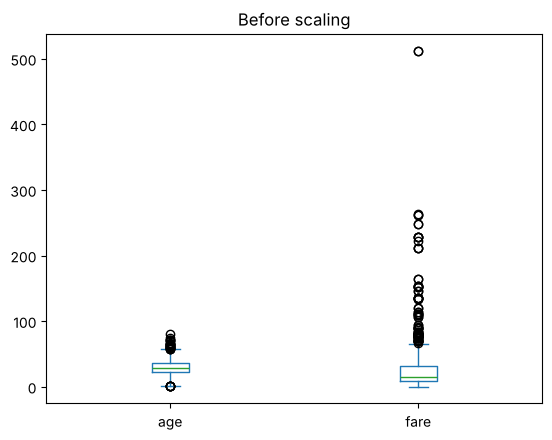

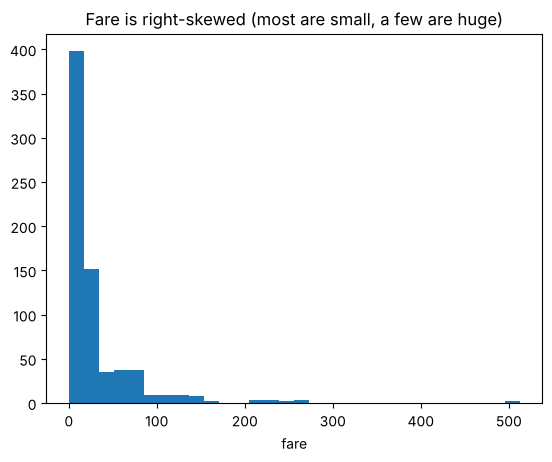

In [6]:
# Graph BEFORE scaling: fare is much bigger than age
X_train[["age", "fare"]].plot(kind="box")
plt.title("Before scaling")
plt.show()

# Histogram of fare
plt.hist(X_train["fare"], bins=30)
plt.title("Fare is right-skewed (most are small, a few are huge)")
plt.xlabel("fare")
plt.show()

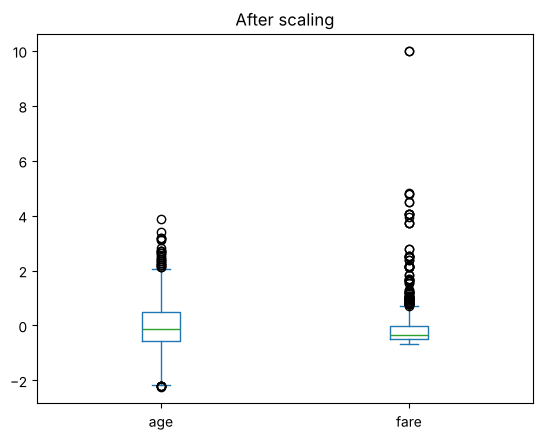

In [7]:
scaler = StandardScaler()

# fit_transform on TRAIN data: learns the mean and std, then scales
X_train[["age", "fare"]] = scaler.fit_transform(X_train[["age", "fare"]])

# only transform on TEST data: uses the train mean and std (no data leakage)
X_test[["age", "fare"]] = scaler.transform(X_test[["age", "fare"]])

# Graph AFTER scaling: both are on a similar scale now
X_train[["age", "fare"]].plot(kind="box")
plt.title("After scaling")
plt.show()

**How to read:** before scaling, `fare` (0 to 500) dwarfs `age` (0 to 80) and has many outliers (dots). After scaling both are centred near 0 on a similar scale. The shape and the outliers stay the same: scaling changes the range, not the shape.

## Step 6: Check that the data is model-ready

In [8]:
print("Missing values left:", X_train.isnull().sum().sum())
print("Any text columns left:", list(X_train.select_dtypes(exclude="number").columns))

# Quick test: a model can now learn from the data
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Test accuracy:", round(model.score(X_test, y_test), 3))

Missing values left: 0
Any text columns left: []
Test accuracy: 0.804


## Conclusion
Missing values were filled (median and mode), text columns were turned into numbers (label and one-hot encoding) and the numeric columns were scaled using the training data only. The data has no missing values and no text, so any ML model can use it.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is feature engineering?**
Creating, transforming and selecting input variables so a model can learn better. It includes cleaning, handling missing values, encoding, scaling, creating new features and selecting useful ones.

**Q2. Why do we handle missing values?**
Most algorithms cannot work with NaN and raise errors. Ignoring them can also bias results.

**Q3. What are the ways to handle missing values?**
Delete rows or columns, fill with mean/median/mode, fill with a constant, forward/backward fill, or model-based imputation (KNN imputer, iterative imputer).

**Q4. When do you use mean, median and mode?**
Mean for symmetric numeric data. Median for skewed data or data with outliers (age, income). Mode for categorical data.

**Q5. Why did you drop the `deck` column?**
About 77% of its values are missing. Filling that many values would invent information, so dropping it is safer.

**Q6. Why did you use the median for `age`?**
Age has outliers and is slightly skewed, and the median is not affected by extreme values, unlike the mean.

**Q7. What are the types of missing data?**
MCAR (missing completely at random), MAR (missing at random, depends on other observed variables) and MNAR (missing not at random, depends on the missing value itself).

**Q8. What is the difference between label encoding and one-hot encoding?**
Label encoding assigns an integer to each category (0, 1, 2) and suits ordinal or binary data. One-hot creates a separate 0/1 column per category and suits nominal data because it does not imply any order.

**Q9. What is the dummy variable trap?**
If you keep all one-hot columns, one column is a perfect combination of the others (perfect multicollinearity). `drop_first=True` removes one column to avoid this.

**Q10. What is ordinal encoding?**
Mapping ordered categories to integers that keep the order, for example Low=0, Medium=1, High=2.

**Q11. Why is scaling needed?**
Features with large ranges (fare in hundreds) can dominate features with small ranges (age). Distance-based and gradient-based algorithms (KNN, SVM, K-Means, PCA, logistic regression, neural networks) need scaled data.

**Q12. Difference between standardisation and normalisation?**
Standardisation: $z = (x - \mu)/\sigma$, giving mean 0 and std 1. Normalisation (min-max): $x' = (x - x_{min})/(x_{max} - x_{min})$, giving values in [0, 1].

**Q13. Which algorithms do not need scaling?**
Tree-based models: Decision Tree, Random Forest, Gradient Boosting.

**Q14. How do outliers affect scaling?**
Min-max scaling is very sensitive to outliers (one huge value squeezes the others). StandardScaler is less affected. RobustScaler uses median and IQR and is the most robust.

**Q15. What is data leakage?**
When information from the test data influences training, for example fitting the scaler on the whole dataset before splitting. It gives falsely good results.

**Q16. What is the difference between `fit`, `transform` and `fit_transform`?**
`fit` learns parameters (mean, std), `transform` applies them, `fit_transform` does both in one step. Use `fit_transform` on train and only `transform` on test.

**Q17. What is a categorical vs numerical variable?**
Categorical holds labels or groups (sex, city). Numerical holds measurable numbers (age, fare); it can be discrete (count) or continuous (height).

**Q18. How do you detect missing values in pandas?**
`df.isnull().sum()` gives counts per column, `df.info()` shows non-null counts, and `sns.heatmap(df.isnull())` shows them visually.

**Q19. What is the difference between feature selection and feature extraction?**
Selection keeps a subset of original features. Extraction creates new features from the old ones (for example PCA).

**Q20. What is a pipeline and why is it useful?**
`sklearn.pipeline.Pipeline` chains steps (imputer, encoder, scaler, model) so they run in order and automatically avoid leakage.

## B. Questions about the graphs

**G1. What does the missing-values heatmap show?**
Rows are samples, columns are features, and yellow marks missing cells. It shows which columns have many gaps (`deck` almost fully missing, `age` scattered) and whether missingness is concentrated.

**G2. What does the boxplot of `age` and `fare` before scaling tell you?**
The two features have very different ranges (fare up to about 500, age up to 80), and `fare` has many outliers (dots above the whisker). That is why scaling is needed.

**G3. What does the histogram of `fare` show?**
It is right-skewed: most passengers paid a low fare, and a few paid very high amounts. For such data the median is a better centre than the mean, and a log transform can reduce skew.

**G4. What changed in the boxplots after scaling?**
Both features now sit on a comparable scale (StandardScaler is centred at 0, MinMax is in [0, 1]), but the shape of the distribution and the outliers are unchanged. Scaling changes range, not shape.

**G5. Does scaling remove outliers?**
No. It only rescales the values; outliers remain.

## C. Code questions

**C1. What does `df['age'].fillna(df['age'].median())` do?**
It replaces every NaN in `age` with the median of that column.

**C2. Why `mode()[0]`?**
`mode()` returns a Series (there can be ties), so `[0]` takes the first most frequent value.

**C3. What does `pd.get_dummies(..., drop_first=True)` do?**
It one-hot encodes the chosen columns and drops the first category of each, avoiding the dummy variable trap.

**C4. Why `stratify=y` in `train_test_split`?**
It keeps the same proportion of survived and not-survived in both train and test sets.

**C5. Why scale only `age` and `fare` and not the 0/1 columns?**
Binary columns are already in [0, 1], so scaling gives no benefit and makes them harder to interpret.